# Corso di Probabilità e Statistica - Teorema del limite centrale

In questo capitolo discutiamo del teorema del limite centrale

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

In [32]:
# usiamo caratteri leggibili!
plt.rcParams.update({'font.size': 18})

**Distribuzione uniforme**

In [33]:
N=4 #numero di variabili da sommare
NR=100000 #numero di realizzazioni

In [34]:
S=np.zeros(NR) # inizializzazione
for i in range(NR):
    S[i]=S[i]+np.sum(np.random.rand(N))/N
    

In [35]:
# Calcoliamo media e varianza
mu_S=np.mean(S)
sigma2_S=np.std(S)
# CLT
mu=0.5
sigma=np.sqrt(1./(12*N))
mu_S,sigma2_S,mu,sigma

(np.float64(0.5001884513061426),
 np.float64(0.14427481220117172),
 0.5,
 np.float64(0.14433756729740643))

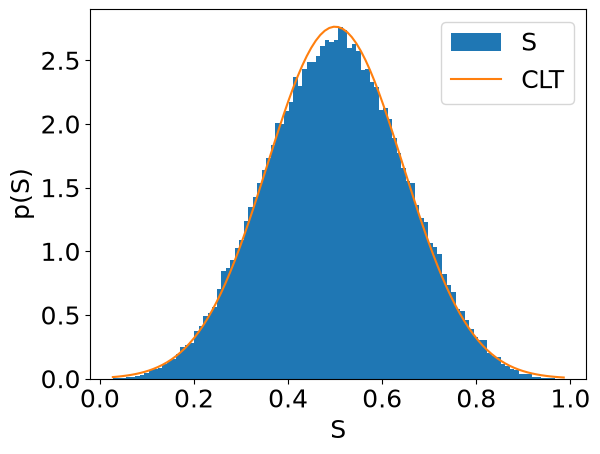

In [36]:
# Istogramma
plt.hist(S,bins=100,density=True,label="S")
# Distribuzione teorica CLT
xmin=np.min(S)
xmax=np.max(S)
x = np.linspace(xmin,xmax,101)
g=stats.norm(loc=mu, scale=sigma) 
plt.plot(x, g.pdf(x), label="CLT")
plt.legend()
plt.xlabel("S")
plt.ylabel("p(S)")
plt.show()


**Esercizio**

Ripetere il calcolo con una distribuzione di variabili esponenziale.

$$ p(x | \lambda) = \lambda \exp(-\lambda x) $$

A parità di N esplorare l'effetto del parametro $\lambda$ sulla convergenza della distribzione della media verso la Gaussiana. 

In [ ]:
N=4 #numero di variabili da sommare
NR=100000 #numero di realizzazioni

In [ ]:
S=np.zeros(NR) # inizializzazione
gamma = 2.5
for i in range(NR):
    S[i]=S[i]+gamma*np.exp(-gamma)
    

**Distribuzione di Levy**

Consideriamo ora la somma di variabili distribuite con una distribuzione a legge di potenza

$$ p(x) = x^{-a} \text{   con  } x>1$$ 

se l'esponente $a<2$ la distribuzione della somma non converge più alla Gaussiana ma alla distribuzione di Levy.

In [37]:
N=1000 #numero di variabili da sommare
NR=100000 #numero di realizzazioni
a=1.5 #esponente

In [38]:
S=np.zeros(NR) # inizializzazione
for i in range(NR):
    x =np.random.rand(N)
    y=(1-x)**(1/(1-a))
    S[i]=S[i]+np.sum(y)/N

In [39]:
# Calcoliamo media e varianza
mu_S=np.mean(S)
sigma_S=np.std(S)

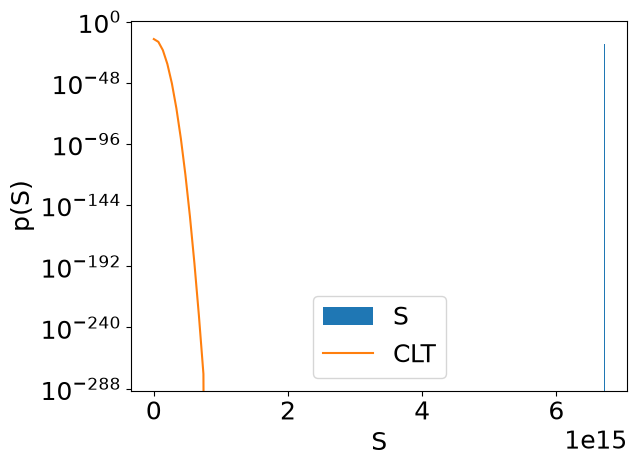

In [40]:
# Istogramma
plt.hist(S,bins=1000,density=True,label="S", log=True)
# Distribuzione teorica CLT
xmin=np.min(S)
xmax=np.max(S)
x = np.linspace(xmin,xmax,101)
g=stats.norm(loc=mu_S, scale=sigma_S) 
plt.plot(x, g.pdf(x), label="CLT")
plt.legend()
plt.xlabel("S")
plt.ylabel("p(S)")
plt.show()

In [41]:
# calcoliamo il logaritmo di S
logS=np.log(S)

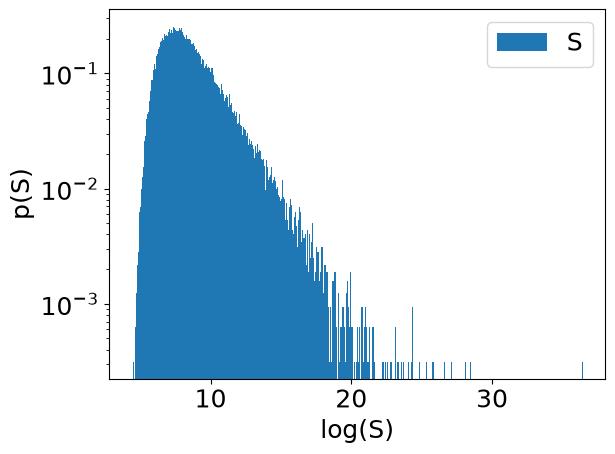

In [46]:
# Istogramma del log in scala log
plt.hist(logS,bins=1000,density=True,label="S", log=True)
plt.legend()
plt.xlabel("log(S)")
plt.ylabel("p(S)")
plt.show()

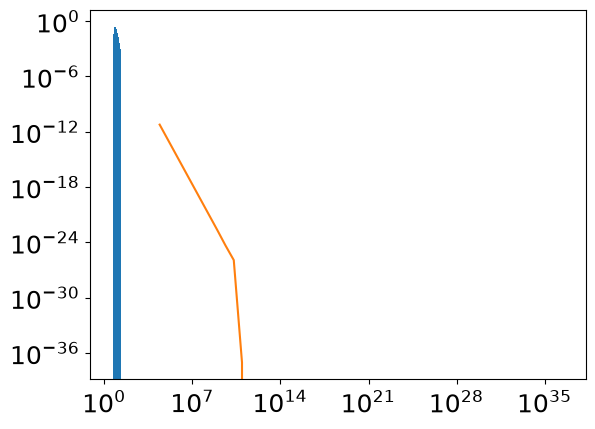

In [54]:
# th Levy
a = 1.5
b = 1.0
levy = stats.levy_stable(alpha=a,beta=b)
plt.hist(logS,bins=1000,density=True,label="S", log=False)
x=np.logspace(np.min(logS),np.max(logS))
plt.loglog(x,levy.pdf(x))
